Code minh họa chuỗi MARKOV

In [1]:
import numpy as np

# ==============================================================================
# 1. KHỞI TẠO MA TRẬN CHUYỂN TRẠNG THÁI VÀ DỰ BÁO SAU n BƯỚC
# ==============================================================================
# 3 trạng thái: [0: Nắng, 1: Mưa, 2: U ám]
P = np.array([
    [0.7, 0.1, 0.2],  # Từ Nắng
    [0.3, 0.4, 0.3],  # Từ Mưa
    [0.4, 0.2, 0.4]   # Từ U ám
])

# Kiểm tra tính hợp lệ: Tổng mỗi hàng phải bằng 1
print("Kiểm tra tổng các hàng ma trận P:", P.sum(axis=1))

# Trạng thái ban đầu: Hôm nay chắc chắn là Trời Nắng -> [1, 0, 0]
pi_0 = np.array([1.0, 0.0, 0.0])

# Dự báo phân phối thời tiết sau 1, 2 và 10 ngày bằng lũy thừa ma trận
pi_1 = pi_0 @ P
pi_2 = pi_0 @ np.linalg.matrix_power(P, 2)
pi_10 = pi_0 @ np.linalg.matrix_power(P, 10)

print(f"\nPhân phối sau 1 ngày : Nắng={pi_1[0]:.3f}, Mưa={pi_1[1]:.3f}, U ám={pi_1[2]:.3f}")
print(f"Phân phối sau 2 ngày : Nắng={pi_2[0]:.3f}, Mưa={pi_2[1]:.3f}, U ám={pi_2[2]:.3f}")
print(f"Phân phối sau 10 ngày: Nắng={pi_10[0]:.3f}, Mưa={pi_10[1]:.3f}, U ám={pi_10[2]:.3f}")

# ==============================================================================
# 2. GIẢI HỆ PHƯƠNG TRÌNH TÌM PHÂN PHỐI DỪNG π (π = π @ P và sum(π) = 1)
# ==============================================================================
# Chuyển π(P - I) = 0 và sum(π) = 1 thành bài toán cực tiểu bình phương tối thiểu
A = np.vstack([P.T - np.eye(3), np.ones(3)])
b = np.array([0.0, 0.0, 0.0, 1.0])
pi_stationary = np.linalg.lstsq(A, b, rcond=None)[0]

print(f"\nPhân phối Dừng lý thuyết (Stationary Distribution π):")
print(f"Tỷ lệ ngày Nắng: {pi_stationary[0] * 100:.2f}%")
print(f"Tỷ lệ ngày Mưa : {pi_stationary[1] * 100:.2f}%")
print(f"Tỷ lệ ngày U ám: {pi_stationary[2] * 100:.2f}%")

# ==============================================================================
# 3. MÔ PHỎNG ĐƯỜNG ĐI NGẪU NHIÊN THỜI TIẾT (RANDOM WALK SIMULATION)
# ==============================================================================
def simulate_markov_chain(P, initial_state_idx, n_steps=15):
    states = ['Nắng', 'Mưa', 'U ám']
    current = initial_state_idx
    trajectory = [states[current]]

    for _ in range(n_steps - 1):
        # Chọn trạng thái tiếp theo dựa trên hàng xác suất P[current]
        current = np.random.choice(3, p=P[current])
        trajectory.append(states[current])
    return trajectory

np.random.seed(42)
weather_walk = simulate_markov_chain(P, initial_state_idx=0, n_steps=15)
print("\nChuỗi thời tiết mô phỏng qua 15 ngày liên tiếp:")
print(" ──► ".join(weather_walk))

Kiểm tra tổng các hàng ma trận P: [1. 1. 1.]

Phân phối sau 1 ngày : Nắng=0.700, Mưa=0.100, U ám=0.200
Phân phối sau 2 ngày : Nắng=0.600, Mưa=0.150, U ám=0.250
Phân phối sau 10 ngày: Nắng=0.545, Mưa=0.182, U ám=0.273

Phân phối Dừng lý thuyết (Stationary Distribution π):
Tỷ lệ ngày Nắng: 54.55%
Tỷ lệ ngày Mưa : 18.18%
Tỷ lệ ngày U ám: 27.27%

Chuỗi thời tiết mô phỏng qua 15 ngày liên tiếp:
Nắng ──► Nắng ──► U ám ──► U ám ──► Mưa ──► Nắng ──► Nắng ──► Nắng ──► U ám ──► U ám ──► U ám ──► Nắng ──► U ám ──► U ám ──► Nắng


Code mô phỏng định lý giới hạn trung tâm

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# 1. MÔ PHỎNG ĐỊNH LÝ GIỚI HẠN TRUNG TÂM (CLT) BẰNG NUMPY
# ==============================================================================
# Lấy mẫu từ phân phối ĐỀU (Uniform - hoàn toàn phẳng, không hề có hình chuông)
np.random.seed(42)
num_samples = 50_000

# Trường hợp 1: Biến ngẫu nhiên gốc (N = 1) -> Phẳng lì
sample_n1 = np.random.uniform(0, 10, size=num_samples)

# Trường hợp 2: Trung bình của N = 5 biến Uniform cộng lại
sample_n5 = np.mean(np.random.uniform(0, 10, size=(num_samples, 5)), axis=1)

# Trường hợp 3: Trung bình của N = 30 biến Uniform cộng lại -> Đường cong Gaussian hoàn hảo!
sample_n30 = np.mean(np.random.uniform(0, 10, size=(num_samples, 30)), axis=1)

print("[Kiểm chứng CLT]:")
print(f"N=1  - Mean: {np.mean(sample_n1):.2f}, Std: {np.std(sample_n1):.2f}")
print(f"N=5  - Mean: {np.mean(sample_n5):.2f}, Std: {np.std(sample_n5):.2f}")
print(f"N=30 - Mean: {np.mean(sample_n30):.2f}, Std: {np.std(sample_n30):.2f} (Hội tụ chuẩn)")

# ==============================================================================
# 2. XÁC THỰC CÔNG THỨC LOSS TỪ NLL BẰNG CODE
# ==============================================================================
def binary_cross_entropy_from_scratch(y_true, y_pred, eps=1e-15):
    """Tính BCE Loss từ công thức NLL của Bernoulli"""
    y_pred = np.clip(y_pred, eps, 1 - eps) # Chống tràn log(0)
    bce = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return bce

y_true = np.array([1, 0, 1, 1, 0])
y_pred = np.array([0.9, 0.1, 0.8, 0.7, 0.2])

loss_bce = binary_cross_entropy_from_scratch(y_true, y_pred)
print(f"\nGiá trị BCE Loss tính từ NLL Bernoulli: {loss_bce:.4f}")

[Kiểm chứng CLT]:
N=1  - Mean: 4.99, Std: 2.88
N=5  - Mean: 5.01, Std: 1.29
N=30 - Mean: 5.00, Std: 0.53 (Hội tụ chuẩn)

Giá trị BCE Loss tính từ NLL Bernoulli: 0.2027


Code MÔ PHỎNG NGHỊCH LÝ DƯƠNG TÍNH GIẢ

In [3]:
# ==============================================================================
# HÀM SUY DIỄN BAYES VÀ MÔ PHỎNG NGHỊCH LÝ DƯƠNG TÍNH GIẢ
# ==============================================================================

def bayes_inference(p_prior, p_likelihood, p_false_alarm):
    """
    Tính xác suất hậu nghiệm P(H|E) theo định lý Bayes.

    Args:
        p_prior: P(H) - Xác suất tiên nghiệm của giả thuyết
        p_likelihood: P(E|H) - Khả năng bằng chứng xuất hiện khi giả thuyết đúng
        p_false_alarm: P(E|~H) - Tỷ lệ báo động giả khi giả thuyết sai
    """
    p_not_h = 1.0 - p_prior
    # Mẫu số: Xác suất toàn phần của bằng chứng E
    p_evidence = p_likelihood * p_prior + p_false_alarm * p_not_h
    p_posterior = (p_likelihood * p_prior) / p_evidence
    return p_posterior, p_evidence

# 1. Thử nghiệm bài toán xét nghiệm y tế
p_disease = 0.0001                # 1 ca trên 10,000 dân
p_pos_given_disease = 0.99       # Độ nhạy 99%
p_pos_given_healthy = 0.05       # 5% dương tính giả

posterior, evidence = bayes_inference(p_disease, p_pos_given_disease, p_pos_given_healthy)
print(f"Tổng xác suất nhận kết quả Dương tính: {evidence * 100:.3f}%")
print(f"P(Thực sự mắc bệnh | Dương tính) = {posterior * 100:.2f}%\n")

# 2. Quan sát sự thay đổi của Posterior khi xét nghiệm lần thứ hai (Cập nhật niềm tin)
# Lấy Posterior của lần 1 làm Prior cho lần xét nghiệm thứ 2:
posterior_test_2, _ = bayes_inference(posterior, p_pos_given_disease, p_pos_given_healthy)
print(f"Nếu xét nghiệm lần 2 tiếp tục Dương tính:")
print(f"P(Thực sự mắc bệnh | Dương tính 2 lần) = {posterior_test_2 * 100:.2f}%")

Tổng xác suất nhận kết quả Dương tính: 5.009%
P(Thực sự mắc bệnh | Dương tính) = 0.20%

Nếu xét nghiệm lần 2 tiếp tục Dương tính:
P(Thực sự mắc bệnh | Dương tính 2 lần) = 3.77%


Xây dựng mô hình Bayes Gaussian bằng NumPy

--- DỮ LIỆU ĐẦU VÀO CẦN DỰ ĐOÁN: [168 158 172] ---
Kết quả (Code tự viết bằng NumPy thuần): ['Nam' 'Nữ' 'Nam']
Kết quả (Thư viện chuẩn scikit-learn)  : ['Nam' 'Nữ' 'Nam']
------------------------------------------------------------
Độ chính xác (Code tự viết)   : 100.00%
Độ chính xác (scikit-learn)   : 100.00%
Hai mô hình dự đoán khớp nhau tuyệt đối True


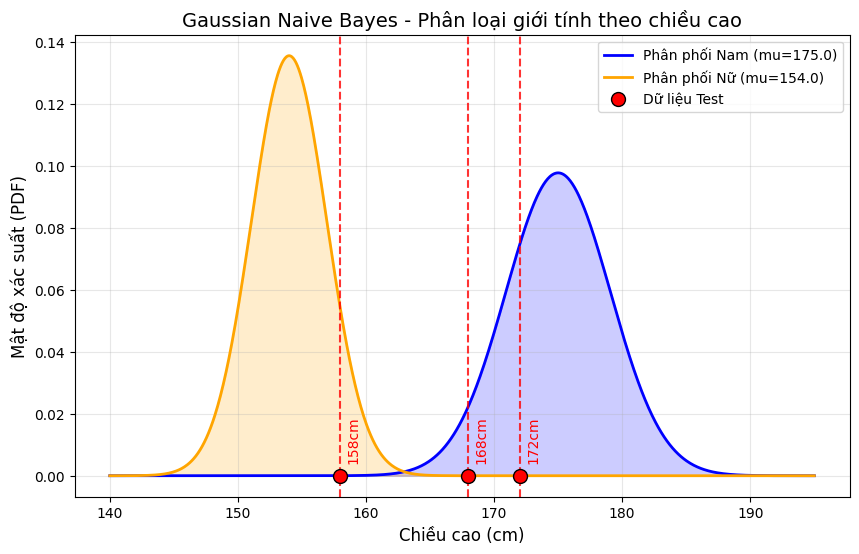

In [ ]:
import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# ==============================================================================
# TỰ XÂY DỰNG CLASS GAUSSIAN NAIVE BAYES FROM SCRATCH (Phiên bản Log-Prob)
# ==============================================================================
class SimpleGaussianNB:
    def __init__(self, eps=1e-9):
        self.eps = eps
        self.classes = None
        self.mean = {}
        self.var = {}
        self.priors = {}

    def fit(self, X, y):
        """
        Pha Huấn luyện (Thống kê suy luận - MLE):
        Tính toán Mean, Variance và Prior cho từng lớp.
        """
        N, d = X.shape
        self.classes = np.unique(y)

        for c in self.classes:
            X_c = X[y == c]
            # 1. MLE cho Prior: P(Y = c)
            self.priors[c] = X_c.shape[0] / N
            # 2. MLE cho Mean: mu
            self.mean[c] = np.mean(X_c, axis=0)
            # 3. MLE cho Variance: sigma^2 (thêm eps chống chia cho 0)
            self.var[c] = np.var(X_c, axis=0) + self.eps

    def _calculate_log_likelihood(self, x, mean, var):
        """Tính log f(x | mu, sigma^2) của phân phối chuẩn"""
        log_pdf = -0.5 * np.log(2.0 * np.pi * var) - 0.5 * ((x - mean) ** 2) / var
        return np.sum(log_pdf)

    def predict(self, X):
        """
        Pha Dự đoán (Xác suất suy diễn - Bayes + Log-Sum trick):
        Tính argmax của log(Prior) + tổng log(Likelihood).
        """
        predictions = []
        for x in X:
            posteriors = []
            for c in self.classes:
                log_prior = np.log(self.priors[c])
                log_likelihood = self._calculate_log_likelihood(
                    x, self.mean[c], self.var[c]
                )
                posteriors.append(log_prior + log_likelihood)
            predictions.append(self.classes[np.argmax(posteriors)])
        return np.array(predictions)
    
    def plot_distributions(self, X_test=None):
        """Vẽ biểu đồ phân phối chuẩn (chỉ áp dụng trực quan tốt cho 1 đặc trưng)"""
        plt.figure(figsize=(10, 6))
        x_axis = np.linspace(140, 195, 1000)
        colors = {"Nam": "blue", "Nữ": "orange"}

        for c in self.classes:
            # Lấy giá trị mean và var của đặc trưng đầu tiên (Chiều cao)
            mu = self.mean[c][0]
            variance = self.var[c][0    ]

            # Hàm PDF chuẩn để vẽ hình chuông
            y_axis = (1 / np.sqrt(2 * np.pi * variance)) * np.exp(
                -0.5 * ((x_axis - mu) ** 2) / variance
            )

            plt.plot(
                x_axis,
                y_axis,
                color=colors[c],
                label=f"Phân phối {c} (mu={mu:.1f})",
                linewidth=2,
            )
            plt.fill_between(x_axis, y_axis, color=colors[c], alpha=0.2)

        # Vẽ các điểm cần dự đoán
        if X_test is not None:
            # Lấy vạch đầu tiên để gán label cho legend, tránh trùng lặp chữ
            first_label = True
            for x_val in X_test.flatten():
                plt.axvline(x=x_val, color="red", linestyle="--", alpha=0.8)
                plt.scatter(
                    [x_val],
                    [0],
                    color="red",
                    s=100,
                    zorder=5,
                    edgecolor="black",
                    label="Dữ liệu Test" if first_label else "",
                )
                plt.text(
                    x_val + 0.5,
                    0.005,
                    f"{x_val}cm",
                    color="red",
                    fontsize=10,
                    rotation=90,
                )
                first_label = False

        plt.title(
            "Gaussian Naive Bayes - Phân loại giới tính theo chiều cao", fontsize=14
        )
        plt.xlabel("Chiều cao (cm)", fontsize=12)
        plt.ylabel("Mật độ xác suất (PDF)", fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

# ==============================================================================
# KIỂM CHỨNG TÍNH CHÍNH XÁC VỚI SCIKIT-LEARN TRÊN DỮ LIỆU CHIỀU CAO
# ==============================================================================
# 1. Chuẩn bị dữ liệu lịch sử (Phải reshape thành mảng 2 chiều)
X_train = np.array(
    [
        [170],
        [175],
        [180],  # Nam
        [155],
        [150],
        [157],  # Nữ
    ]
)
y_train = np.array(["Nam", "Nam", "Nam", "Nữ", "Nữ", "Nữ"])

# Dữ liệu cần dự đoán (3 người mới bước vào phòng)
X_test = np.array(
    [
        [168],  # Gần Nam hơn
        [158],  # Gần Nữ hơn
        [172],  # Chắc chắn Nam
    ]
)
# Nhãn thực tế (để tính độ chính xác)
y_test = np.array(["Nam", "Nữ", "Nam"])

# 2. Huấn luyện mô hình tự code bằng NumPy
my_model = SimpleGaussianNB()
my_model.fit(X_train, y_train)
y_pred_my = my_model.predict(X_test)

# 3. Huấn luyện mô hình chuẩn của scikit-learn
sklearn_model = GaussianNB()
sklearn_model.fit(X_train, y_train)
y_pred_sklearn = sklearn_model.predict(X_test)

# 4. So sánh kết quả đối đầu
print(f"--- DỮ LIỆU ĐẦU VÀO CẦN DỰ ĐOÁN: {X_test.flatten()} ---")
print(f"Kết quả (Code tự viết bằng NumPy thuần): {y_pred_my}")
print(f"Kết quả (Thư viện chuẩn scikit-learn)  : {y_pred_sklearn}")
print("-" * 60)
print(f"Độ chính xác (Code tự viết)   : {accuracy_score(y_test, y_pred_my) * 100:.2f}%")
print(
    f"Độ chính xác (scikit-learn)   : {accuracy_score(y_test, y_pred_sklearn) * 100:.2f}%"
)
print(
    "Hai mô hình dự đoán khớp nhau tuyệt đối",
    np.array_equal(y_pred_my, y_pred_sklearn),
)
my_model.plot_distributions(X_test)


Code xây dựng Categorical Naive Bayes

In [ ]:
import numpy as np

# ==============================================================================
# 1. TẠO TẬP DỮ LIỆU HUẤN LUYỆN BÀI TOÁN PLAY TENNIS
# Cột 0: Outlook (Sunny, Overcast, Rain)
# Cột 1: Temperature (Hot, Mild, Cool)
# Cột 2: Humidity (High, Normal) : Độ ẩm
# Cột 3: Wind (Weak, Strong)
# Cột 4: Play Tennis (no, yes) - Nhãn mục tiêu
# ==============================================================================
def create_train_data():
    data = [
        ["Sunny", "Hot", "High", "Weak", "no"],
        ["Sunny", "Hot", "High", "Strong", "no"],
        ["Overcast", "Hot", "High", "Weak", "yes"],
        ["Rain", "Mild", "High", "Weak", "yes"],
        ["Rain", "Cool", "Normal", "Weak", "yes"],
        ["Rain", "Cool", "Normal", "Strong", "no"],
        ["Overcast", "Cool", "Normal", "Strong", "yes"],
        ["Overcast", "Mild", "High", "Weak", "no"],
        ["Sunny", "Cool", "Normal", "Weak", "yes"],
        ["Rain", "Mild", "Normal", "Weak", "yes"]
    ]
    return np.array(data) # 4 NO 6 Yes

# ==============================================================================
# 2. TÍNH XÁC SUẤT TIÊN NGHIỆM P(Y = c)
# ==============================================================================
def compute_prior_probability(train_data):
    y_unique = ['no', 'yes']
    prior_probability = np.zeros(len(y_unique))
    total = len(train_data)
    label_column = train_data[:, -1]

    for i, label in enumerate(y_unique):
        count = np.sum(label_column == label)
        prior_probability[i] = count / total
    return prior_probability #[0.4,0.6]

# ==============================================================================
# 3. TÍNH BẢNG XÁC SUẤT CÓ ĐIỀU KIỆN P(X_i = v | Y = c)
# ==============================================================================
def compute_conditional_probability(train_data):
    y_unique = ['no', 'yes']
    conditional_probability = []
    list_x_name = []

    # Duyệt qua từng cột đặc trưng (bỏ cột nhãn cuối cùng)
    for i in range(0, train_data.shape[1] - 1): #.shape[1] là cột =>train_data.shape[1] - 1=4
        x_unique = np.unique(train_data[:, i]) #np.unique() tự động sắp xếp các giá trị theo thứ tự từ điển.
        list_x_name.append(x_unique)

        x_cond_prob = np.zeros((len(y_unique), len(x_unique)))
        for y_idx, y_val in enumerate(y_unique):
            samples_in_class = train_data[train_data[:, -1] == y_val]
            total_samples = len(samples_in_class)
            for x_idx, x_val in enumerate(x_unique): #x_unique=["Overcast","Rain","Sunny"]
                count = np.sum(samples_in_class[:, i] == x_val)# lấy tất cả các hàng ở cột thứ i(outlook) và xét xem bằng x_val(Overcast)
                x_cond_prob[y_idx, x_idx] = count / total_samples

        conditional_probability.append(x_cond_prob) #lưu matrix của 4 cột features
    return conditional_probability, list_x_name
'''
conditional_probability: Tra cứu (ma trận) xác suất của giá trị cần dự đoán.
list_x_name: Xác định giá trị đó nằm ở cột nào trong ma trận xác suất.
'''
def get_index_from_value(feature_name, list_features):
    """Tìm chỉ số vị trí của giá trị đặc trưng trong danh  sách"""
    return np.where(list_features == feature_name)[0][0]

# ==============================================================================
# 4. HUẤN LUYỆN MÔ HÌNH CATEGORICAL NAIVE BAYES
# ==============================================================================
def train_naive_bayes(train_data):
    prior_prob = compute_prior_probability(train_data)
    cond_prob, list_x_name = compute_conditional_probability(train_data)
    return prior_prob, cond_prob, list_x_name
# ==============================================================================
# 5. DỰ ĐOÁN QUYẾT ĐỊNH CHO MẪU MỚI
# ==============================================================================
def prediction_play_tennis(X, list_x_name, prior_prob, cond_prob):
    # Lấy chỉ số tương ứng của từng đặc trưng
    x1 = get_index_from_value(X[0], list_x_name[0])
    x2 = get_index_from_value(X[1], list_x_name[1])
    x3 = get_index_from_value(X[2], list_x_name[2])
    x4 = get_index_from_value(X[3], list_x_name[3])

    # Tính P(X | Y=no) * P(Y=no)
    p0 = prior_prob[0] * cond_prob[0][0, x1] * cond_prob[1][0, x2] * cond_prob[2][0, x3] * cond_prob[3][0, x4]
    # Tính P(X | Y=yes) * P(Y=yes)
    p1 = prior_prob[1] * cond_prob[0][1, x1] * cond_prob[1][1, x2] * cond_prob[2][1, x3] * cond_prob[3][1, x4]

    y_pred = 0 if p0 > p1 else 1
    return y_pred, p0, p1

# ==============================================================================
# 6. CHẠY THỰC NGHIỆM
# ==============================================================================
train_data = create_train_data()
prior, cond, x_names = train_naive_bayes(train_data)

print("[2. Kiểm chứng Categorical Naive Bayes trên Bài toán Play Tennis]:")
print(f"Xác suất Tiên nghiệm: P(No) = {prior[0]:.2f}, P(Yes) = {prior[1]:.2f}")

# Quan sát một số xác suất điều kiện:
i_sunny = get_index_from_value("Sunny", x_names[0])
print(f"P('Outlook'='Sunny' | 'Yes') = {cond[0][1, i_sunny]:.2f}")
print(f"P('Outlook'='Sunny' | 'No')  = {cond[0][0, i_sunny]:.2f}")

# Thử nghiệm dự đoán cho một ngày thời tiết mới:
X_new = ['Sunny', 'Cool', 'High', 'Strong']
pred_result, p_no, p_yes = prediction_play_tennis(X_new, x_names, prior, cond)

print(f"\nDự đoán cho ngày thời tiết: {X_new}")
print(f"Tích xác suất Posterior (No) : {p_no:.6f}")
print(f"Tích xác suất Posterior (Yes): {p_yes:.6f}")
print(f"Quyết định: {'NÊN ĐI CHƠI TENNIS (Yes)' if pred_result == 1 else 'KHÔNG NÊN ĐI (No)'}\n")

[2. Kiểm chứng Categorical Naive Bayes trên Bài toán Play Tennis]:
Xác suất Tiên nghiệm: P(No) = 0.40, P(Yes) = 0.60
P('Outlook'='Sunny' | 'Yes') = 0.17
P('Outlook'='Sunny' | 'No')  = 0.50

Dự đoán cho ngày thời tiết: ['Sunny', 'Cool', 'High', 'Strong']
Tích xác suất Posterior (No) : 0.018750
Tích xác suất Posterior (Yes): 0.002778
Quyết định: KHÔNG NÊN ĐI (No)



Nếu dùng thư viện thì sao? Thì nhanh hơn rất nhiều nhưng vì đây là giai đoạn đầu
chúng ta cần hiểu bản chất, đi chậm mà chắc.

In [1]:
import numpy as np
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, classification_report

# ============================================================
# 1. CREATE DATASET
# ============================================================

def create_train_data():
    data = [
        ["Sunny", "Hot", "High", "Weak", "no"],
        ["Sunny", "Hot", "High", "Strong", "no"],
        ["Overcast", "Hot", "High", "Weak", "yes"],
        ["Rain", "Mild", "High", "Weak", "yes"],
        ["Rain", "Cool", "Normal", "Weak", "yes"],
        ["Rain", "Cool", "Normal", "Strong", "no"],
        ["Overcast", "Cool", "Normal", "Strong", "yes"],
        ["Overcast", "Mild", "High", "Weak", "no"],
        ["Sunny", "Cool", "Normal", "Weak", "yes"],
        ["Rain", "Mild", "Normal", "Weak", "yes"]
    ]
    return np.array(data)


# ============================================================
# 2. SPLIT FEATURES AND LABEL
# ============================================================

train_data = create_train_data()

X = train_data[:, :-1]  # 4 feature columns
y = train_data[:, -1]   # Target column

# ============================================================
# 3. ENCODE CATEGORICAL FEATURES
# ============================================================

encoder = OrdinalEncoder()

X_encoded = encoder.fit_transform(X).astype(int)

print("Encoded X:")
print(X_encoded)

# ============================================================
# 4. TRAIN CATEGORICAL NAIVE BAYES
# ============================================================

model = CategoricalNB(alpha=1.0)

model.fit(X_encoded, y)

# ============================================================
# 5. PREDICTION
# ============================================================

X_new = np.array([
    ["Sunny", "Cool", "High", "Strong"]
])

X_new_encoded = encoder.transform(X_new).astype(int)

y_pred = model.predict(X_new_encoded)

y_proba = model.predict_proba(X_new_encoded)

print("\nNew weather:", X_new[0])
print("Predicted label:", y_pred[0])

print("\nPosterior probabilities:")
for label, probability in zip(model.classes_, y_proba[0]):
    print(f"P({label} | X) = {probability:.6f}")


Encoded X:
[[2 1 0 1]
 [2 1 0 0]
 [0 1 0 1]
 [1 2 0 1]
 [1 0 1 1]
 [1 0 1 0]
 [0 0 1 0]
 [0 2 0 1]
 [2 0 1 1]
 [1 2 1 1]]

New weather: ['Sunny' 'Cool' 'High' 'Strong']
Predicted label: no

Posterior probabilities:
P(no | X) = 0.746114
P(yes | X) = 0.253886
